Imports and sample dataset

In [1]:

# Cell 2: Imports and sample dataset

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import TfidfVectorizer

documents = [
    {
        "id": "D1",
        "title": "RAG Introduction",
        "text": (
            "Retrieval-Augmented Generation combines information retrieval "
            "with a language model. It retrieves relevant external documents "
            "and uses them as context to generate grounded answers."
        )
    },
    {
        "id": "D2",
        "title": "Fine-Tuning",
        "text": (
            "Fine-tuning updates a pretrained model using additional training "
            "examples. It can adapt model behavior, terminology, output format, "
            "and task performance. It does not automatically keep factual "
            "knowledge current."
        )
    },
    {
        "id": "D3",
        "title": "Embedding Models",
        "text": (
            "Embedding models convert text into numerical vectors. Similar "
            "meanings are often represented by vectors that are close in "
            "embedding space. Cosine similarity is commonly used to compare "
            "text embeddings."
        )
    },
    {
        "id": "D4",
        "title": "Chunking",
        "text": (
            "Chunking divides long documents into smaller text segments. "
            "Chunk size and overlap influence retrieval quality. Overlap helps "
            "preserve context across boundaries, but excessive overlap creates "
            "redundant chunks."
        )
    },
    {
        "id": "D5",
        "title": "Vector Databases",
        "text": (
            "A vector database stores embeddings and supports similarity "
            "search. FAISS provides efficient nearest-neighbor search over "
            "vectors, while production vector databases can also support "
            "metadata filters and persistent storage."
        )
    },
    {
        "id": "D6",
        "title": "Dense Passage Retrieval",
        "text": (
            "Dense Passage Retrieval, or DPR, uses neural question and passage "
            "encoders to represent queries and passages as dense vectors. "
            "Passages are ranked using vector similarity or dot products."
        )
    },
    {
        "id": "D7",
        "title": "RAG Pipeline",
        "text": (
            "A typical RAG pipeline loads documents, cleans text, chunks "
            "documents, generates embeddings, indexes vectors, retrieves "
            "relevant passages, constructs a prompt, and generates an answer."
        )
    },
    {
        "id": "D8",
        "title": "Retrieval-Augmented Prompting",
        "text": (
            "Retrieval-augmented prompting places retrieved evidence inside "
            "the language model prompt. Instructions should tell the model "
            "to answer from the evidence and acknowledge missing information."
        )
    },
    {
        "id": "D9",
        "title": "Agentic RAG",
        "text": (
            "Agentic RAG uses an agent to plan retrieval steps, choose tools, "
            "refine queries, and decide whether more evidence is needed. "
            "It can use iterative retrieval rather than a single search."
        )
    },
    {
        "id": "D10",
        "title": "Multimodal RAG",
        "text": (
            "Multimodal RAG retrieves information from multiple modalities, "
            "such as text, images, audio, and video. A shared embedding space "
            "or modality-specific retrieval systems can connect user queries "
            "to relevant media."
        )
    }
]

df = pd.DataFrame(documents)
display(df[["id", "title", "text"]])

print("Total documents:", len(df))


,id,title,text
0,D1,RAG Introduction,Retrieval-Augmented Generation combines inform...
1,D2,Fine-Tuning,Fine-tuning updates a pretrained model using a...
2,D3,Embedding Models,Embedding models convert text into numerical v...
3,D4,Chunking,Chunking divides long documents into smaller t...
4,D5,Vector Databases,A vector database stores embeddings and suppor...
5,D6,Dense Passage Retrieval,"Dense Passage Retrieval, or DPR, uses neural q..."
6,D7,RAG Pipeline,"A typical RAG pipeline loads documents, cleans..."
7,D8,Retrieval-Augmented Prompting,Retrieval-augmented prompting places retrieved...
8,D9,Agentic RAG,Agentic RAG uses an agent to plan retrieval st...
9,D10,Multimodal RAG,Multimodal RAG retrieves information from mult...


Total documents: 10


In [2]:

# Cell 3: A simple RAG algorithm

def simple_rag(query, knowledge_base):
    """
    Baseline retrieval using word overlap.
    This is an educational baseline, not semantic retrieval.
    """
    query_words = set(query.lower().split())
    ranked = []

    for doc in knowledge_base:
        text = doc["text"].lower()
        score = sum(word in text for word in query_words)

        ranked.append({
            "id": doc["id"],
            "title": doc["title"],
            "score": score,
            "text": doc["text"]
        })

    return sorted(
        ranked,
        key=lambda item: item["score"],
        reverse=True
    )

results = simple_rag(
    "How does a vector database retrieve information?",
    documents
)

for result in results[:3]:
    print(result["id"], result["title"], result["score"])
    print(result["text"], "\n")


D5 Vector Databases 3
A vector database stores embeddings and supports similarity search. FAISS provides efficient nearest-neighbor search over vectors, while production vector databases can also support metadata filters and persistent storage. 

D7 RAG Pipeline 3
A typical RAG pipeline loads documents, cleans text, chunks documents, generates embeddings, indexes vectors, retrieves relevant passages, constructs a prompt, and generates an answer. 

D1 RAG Introduction 2
Retrieval-Augmented Generation combines information retrieval with a language model. It retrieves relevant external documents and uses them as context to generate grounded answers. 



In [3]:

# Cell 4: Compare retrieval-grounded context with model-only knowledge

query = "What is DPR, and how does it retrieve passages?"

retrieved = simple_rag(query, documents)[:2]

rag_context = "\n".join(
    item["text"] for item in retrieved
)

model_only_answer = (
    "DPR is a neural retrieval method that represents questions "
    "and passages as dense vectors."
)

rag_grounded_answer = (
    "Based on the retrieved evidence:\n" + rag_context
)

print("QUERY:", query)
print("\nMODEL-ONLY BASELINE:\n", model_only_answer)
print("\nRAG-GROUNDED EVIDENCE:\n", rag_grounded_answer)


QUERY: What is DPR, and how does it retrieve passages?

MODEL-ONLY BASELINE:
 DPR is a neural retrieval method that represents questions and passages as dense vectors.

RAG-GROUNDED EVIDENCE:
 Based on the retrieved evidence:
Retrieval-Augmented Generation combines information retrieval with a language model. It retrieves relevant external documents and uses them as context to generate grounded answers.
Fine-tuning updates a pretrained model using additional training examples. It can adapt model behavior, terminology, output format, and task performance. It does not automatically keep factual knowledge current.


In [4]:

# Cell 5: Word-based chunking

def chunk_text(text, chunk_size=40, overlap=10):
    """
    Split text into word chunks.
    overlap must be smaller than chunk_size.
    """
    if chunk_size <= 0:
        raise ValueError("chunk_size must be positive")

    if overlap < 0 or overlap >= chunk_size:
        raise ValueError("overlap must be in [0, chunk_size)")

    words = text.split()
    chunks = []
    step = chunk_size - overlap

    for start in range(0, len(words), step):
        chunk = " ".join(words[start:start + chunk_size])

        if chunk:
            chunks.append(chunk)

        if start + chunk_size >= len(words):
            break

    return chunks


long_text = " ".join(doc["text"] for doc in documents)

chunks = chunk_text(
    long_text,
    chunk_size=35,
    overlap=8
)

for i, chunk in enumerate(chunks[:5]):
    print(f"Chunk {i + 1}: {chunk}\n")

print("Total chunks:", len(chunks))


Chunk 1: Retrieval-Augmented Generation combines information retrieval with a language model. It retrieves relevant external documents and uses them as context to generate grounded answers. Fine-tuning updates a pretrained model using additional training examples. It can adapt

Chunk 2: model using additional training examples. It can adapt model behavior, terminology, output format, and task performance. It does not automatically keep factual knowledge current. Embedding models convert text into numerical vectors. Similar meanings are often

Chunk 3: text into numerical vectors. Similar meanings are often represented by vectors that are close in embedding space. Cosine similarity is commonly used to compare text embeddings. Chunking divides long documents into smaller text segments. Chunk

Chunk 4: divides long documents into smaller text segments. Chunk size and overlap influence retrieval quality. Overlap helps preserve context across boundaries, but excessive overlap creates redund

In [5]:

# Cell 6: Experiment with chunk size and overlap

settings = [
    (20, 0),
    (35, 8),
    (60, 15)
]

for size, overlap in settings:
    current_chunks = chunk_text(
        long_text,
        chunk_size=size,
        overlap=overlap
    )

    print(
        f"Chunk size={size}, overlap={overlap}: "
        f"{len(current_chunks)} chunks"
    )


Chunk size=20, overlap=0: 14 chunks
Chunk size=35, overlap=8: 10 chunks
Chunk size=60, overlap=15: 6 chunks


In [6]:

# Cell 7: Generate semantic embeddings

embedding_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

texts = [
    doc["title"] + ". " + doc["text"]
    for doc in documents
]

embeddings = embedding_model.encode(
    texts,
    convert_to_numpy=True,
    normalize_embeddings=True,
    show_progress_bar=True
)

print("Embedding shape:", embeddings.shape)
print("First vector dimensions:", embeddings[0][:10])


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Embedding shape: (10, 384)
First vector dimensions: [-0.0865113  -0.00435369 -0.0270313   0.06322493 -0.01414078  0.08182692
  0.03398896  0.05913997  0.01605097 -0.06314124]


In [7]:

# Cell 8: Cosine similarity

queries = [
    "How can a language model use external knowledge?",
    "How do neural networks represent sentence meaning?",
    "How do I divide a large document into smaller pieces?"
]

query_vectors = embedding_model.encode(
    queries,
    convert_to_numpy=True,
    normalize_embeddings=True
)

similarities = query_vectors @ embeddings.T

for qi, query in enumerate(queries):
    ranked_indices = np.argsort(
        similarities[qi]
    )[::-1][:3]

    print("\nQUERY:", query)

    for idx in ranked_indices:
        print(
            f"{similarities[qi, idx]:.3f}",
            documents[idx]["id"],
            documents[idx]["title"]
        )



QUERY: How can a language model use external knowledge?
0.411 D8 Retrieval-Augmented Prompting
0.344 D1 RAG Introduction
0.295 D2 Fine-Tuning

QUERY: How do neural networks represent sentence meaning?
0.415 D3 Embedding Models
0.324 D8 Retrieval-Augmented Prompting
0.282 D1 RAG Introduction

QUERY: How do I divide a large document into smaller pieces?
0.553 D4 Chunking
0.226 D7 RAG Pipeline
0.117 D6 Dense Passage Retrieval


In [10]:

# Cell 9: Create a FAISS vector index

import faiss

dimension = embeddings.shape[1]

# The embeddings are normalized, so inner product
# corresponds to cosine similarity.
index = faiss.IndexFlatIP(dimension)
index.add(embeddings.astype("float32"))

print("Indexed vectors:", index.ntotal)


def vector_search(query, k=3):
    query_vector = embedding_model.encode(
        [query],
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")

    scores, indices = index.search(
        query_vector,
        min(k, len(documents))
    )

    output = []

    for score, idx in zip(scores[0], indices[0]):
        if idx >= 0:
            output.append({
                "id": documents[idx]["id"],
                "title": documents[idx]["title"],
                "text": documents[idx]["text"],
                "score": float(score)
            })

    return output


for item in vector_search(
    "How do I search semantically through a knowledge base?",
    k=3
):
    print(item["score"], item["title"])
    print(item["text"], "\n")


Indexed vectors: 10
0.368367463350296 Vector Databases
A vector database stores embeddings and supports similarity search. FAISS provides efficient nearest-neighbor search over vectors, while production vector databases can also support metadata filters and persistent storage. 

0.320695161819458 RAG Introduction
Retrieval-Augmented Generation combines information retrieval with a language model. It retrieves relevant external documents and uses them as context to generate grounded answers. 

0.2910012900829315 Retrieval-Augmented Prompting
Retrieval-augmented prompting places retrieved evidence inside the language model prompt. Instructions should tell the model to answer from the evidence and acknowledge missing information. 



In [11]:

# Cell 10: Save and reload the FAISS index

faiss.write_index(index, "/content/rag_index.faiss")

loaded_index = faiss.read_index(
    "/content/rag_index.faiss"
)

print("Reloaded vectors:", loaded_index.ntotal)


Reloaded vectors: 10


In [12]:

# Cell 11: Load pretrained DPR question and passage encoders

from transformers import (
    DPRQuestionEncoder,
    DPRQuestionEncoderTokenizer,
    DPRContextEncoder,
    DPRContextEncoderTokenizer
)

device = "cuda" if torch.cuda.is_available() else "cpu"

question_model_name = (
    "facebook/dpr-question_encoder-single-nq-base"
)
context_model_name = (
    "facebook/dpr-ctx_encoder-single-nq-base"
)

question_tokenizer = DPRQuestionEncoderTokenizer.from_pretrained(
    question_model_name
)
question_encoder = DPRQuestionEncoder.from_pretrained(
    question_model_name
).to(device).eval()

context_tokenizer = DPRContextEncoderTokenizer.from_pretrained(
    context_model_name
)
context_encoder = DPRContextEncoder.from_pretrained(
    context_model_name
).to(device).eval()

print("DPR encoders loaded on:", device)


tokenizer_config.json:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/493 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

...

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] DPRContextEncoder LOAD REPORT from: facebook/dpr-ctx_encoder-single-nq-base
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
ctx_encoder.bert_model.pooler.dense.bias   | UNEXPECTED |  | 
ctx_encoder.bert_model.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


DPR encoders loaded on: cuda


In [13]:

# Cell 12: Build the DPR passage index

passages = [
    doc["title"] + ". " + doc["text"]
    for doc in documents
]

context_inputs = context_tokenizer(
    passages,
    padding=True,
    truncation=True,
    max_length=256,
    return_tensors="pt"
).to(device)

with torch.no_grad():
    passage_vectors = context_encoder(
        **context_inputs
    ).pooler_output

passage_vectors = passage_vectors.cpu().numpy().astype("float32")

dpr_index = faiss.IndexFlatIP(
    passage_vectors.shape[1]
)
dpr_index.add(passage_vectors)

print("DPR passages indexed:", dpr_index.ntotal)


DPR passages indexed: 10


In [14]:

# Cell 13: DPR retrieval

def dpr_search(question, k=3):
    inputs = question_tokenizer(
        question,
        return_tensors="pt",
        truncation=True,
        max_length=128
    ).to(device)

    with torch.no_grad():
        q_vector = question_encoder(
            **inputs
        ).pooler_output

    q_vector = q_vector.cpu().numpy().astype("float32")

    scores, indices = dpr_index.search(
        q_vector,
        min(k, len(passages))
    )

    return [
        {
            "title": documents[i]["title"],
            "text": documents[i]["text"],
            "score": float(score)
        }
        for score, i in zip(scores[0], indices[0])
        if i >= 0
    ]


for result in dpr_search(
    "How can I retrieve passages using neural encoders?",
    k=3
):
    print(result["score"], result["title"])
    print(result["text"], "\n")


78.25364685058594 Dense Passage Retrieval
Dense Passage Retrieval, or DPR, uses neural question and passage encoders to represent queries and passages as dense vectors. Passages are ranked using vector similarity or dot products. 

68.33194732666016 Retrieval-Augmented Prompting
Retrieval-augmented prompting places retrieved evidence inside the language model prompt. Instructions should tell the model to answer from the evidence and acknowledge missing information. 

67.35365295410156 Agentic RAG
Agentic RAG uses an agent to plan retrieval steps, choose tools, refine queries, and decide whether more evidence is needed. It can use iterative retrieval rather than a single search. 



In [15]:

# Cell 14: Load the language model

from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM
)

generator_name = "google/flan-t5-base"

generator_tokenizer = AutoTokenizer.from_pretrained(
    generator_name
)

generator_model = AutoModelForSeq2SeqLM.from_pretrained(
    generator_name
).to(device).eval()

print("Generator loaded on:", device)


config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Generator loaded on: cuda


In [16]:

# Cell 15: Complete RAG pipeline

def retrieve_context(query, k=3):
    results = vector_search(query, k=k)

    context = "\n\n".join(
        f"[{item['id']}] {item['title']}: {item['text']}"
        for item in results
    )

    return results, context


def generate_grounded_answer(query, context):
    prompt = f"""
Answer the question using only the evidence below.
If the evidence does not contain the answer, say:
"I don't have enough information in the provided documents."

Evidence:
{context}

Question: {query}

Answer:
"""

    inputs = generator_tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=1024
    ).to(device)

    with torch.no_grad():
        output = generator_model.generate(
            **inputs,
            max_new_tokens=160,
            num_beams=2,
            do_sample=False
        )

    return generator_tokenizer.decode(
        output[0],
        skip_special_tokens=True
    )


def rag_pipeline(query, k=3):
    results, context = retrieve_context(query, k=k)
    answer = generate_grounded_answer(query, context)

    return {
        "question": query,
        "answer": answer,
        "sources": results
    }


result = rag_pipeline(
    "Explain how embeddings and vector search help a RAG system."
)

print("QUESTION:", result["question"])
print("\nANSWER:", result["answer"])
print("\nSOURCES:")

for source in result["sources"]:
    print(source["id"], source["title"], source["score"])


QUESTION: Explain how embeddings and vector search help a RAG system.

ANSWER: [D7] RAG Pipeline: A typical RAG pipeline loads documents, cleans text, chunks documents, generates embeddings, indexes vectors, retrieves relevant passages, constructs a prompt, and generates an answer.

SOURCES:
D10 Multimodal RAG 0.5873329639434814
D7 RAG Pipeline 0.5544315576553345
D9 Agentic RAG 0.5005902051925659


In [17]:

# Cell 16: Compare prompting strategies

def build_prompt(query, context, strategy="grounded"):
    if strategy == "basic":
        return f"""
Context:
{context}

Question: {query}
Answer:
"""

    if strategy == "grounded":
        return f"""
You are a careful question-answering assistant.

Rules:
1. Use the supplied context as your evidence.
2. Do not invent facts absent from the context.
3. If the evidence is insufficient, state that clearly.
4. Give a concise answer.
5. Refer to evidence IDs such as [D3] when useful.

Context:
{context}

Question: {query}

Evidence-based answer:
"""

    raise ValueError("Unknown prompt strategy")


def answer_with_strategy(query, strategy):
    results, context = retrieve_context(query, k=3)
    prompt = build_prompt(query, context, strategy)

    inputs = generator_tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=1024
    ).to(device)

    with torch.no_grad():
        output = generator_model.generate(
            **inputs,
            max_new_tokens=160,
            do_sample=False
        )

    answer = generator_tokenizer.decode(
        output[0],
        skip_special_tokens=True
    )

    return answer, results


test_question = "What does chunk overlap do?"

for strategy in ["basic", "grounded"]:
    answer, sources = answer_with_strategy(
        test_question,
        strategy
    )

    print(f"\n--- {strategy.upper()} PROMPT ---")
    print(answer)



--- BASIC PROMPT ---
preserve context across boundaries

--- GROUNDED PROMPT ---
preserve context across boundaries.


In [18]:

# Cell 17: Agent tools

def semantic_search_tool(query):
    return vector_search(query, k=3)


def keyword_search_tool(query):
    from rank_bm25 import BM25Okapi

    tokenized_docs = [
        (doc["title"] + " " + doc["text"]).lower().split()
        for doc in documents
    ]

    bm25 = BM25Okapi(tokenized_docs)
    scores = bm25.get_scores(query.lower().split())

    top_indices = np.argsort(scores)[::-1][:3]

    return [
        {
            "id": documents[i]["id"],
            "title": documents[i]["title"],
            "text": documents[i]["text"],
            "score": float(scores[i])
        }
        for i in top_indices
    ]


def choose_tool(query):
    q = query.lower()

    if any(word in q for word in [
        "exact phrase", "keyword", "specific word"
    ]):
        return "keyword"

    return "semantic"


def agentic_rag(query):
    # Step 1: Choose a tool.
    tool_name = choose_tool(query)

    # Step 2: Retrieve evidence.
    if tool_name == "keyword":
        results = keyword_search_tool(query)
    else:
        results = semantic_search_tool(query)

    # Step 3: Inspect retrieval and retry if necessary.
    # This threshold is a heuristic, not a calibrated probability.
    if not results or results[0]["score"] < 0.20:
        retry_query = query + " definition explanation"
        results = semantic_search_tool(retry_query)

    # Step 4: Generate from the final evidence.
    context = "\n\n".join(
        f"[{item['id']}] {item['title']}: {item['text']}"
        for item in results
    )

    answer = generate_grounded_answer(query, context)

    return {
        "selected_tool": tool_name,
        "answer": answer,
        "sources": results
    }


agent_result = agentic_rag(
    "Explain how neural embeddings support retrieval."
)

print("Selected tool:", agent_result["selected_tool"])
print("\nAnswer:", agent_result["answer"])
print("\nEvidence:")

for source in agent_result["sources"]:
    print(source["id"], source["title"])


Selected tool: semantic

Answer: [D3] Embedding models convert text into numerical vectors. Similar meanings are often represented by vectors that are close in embedding space. Cosine similarity is commonly used to compare text embeddings. [D1] Retrieval-Augmented Generation combines information retrieval with a language model. It retrieves relevant external documents and uses them as context to generate grounded answers. [D8] Retrieval-Augmented Prompting places retrieved evidence inside the language model prompt. Instruction should tell the model to answer from the evidence and acknowledge missing information.

Evidence:
D3 Embedding Models
D1 RAG Introduction
D8 Retrieval-Augmented Prompting


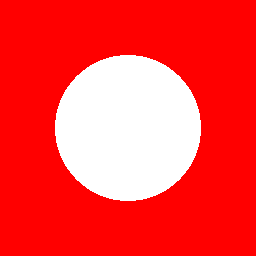

A white circle on a red background


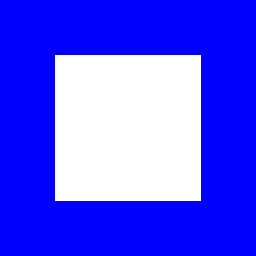

A white square on a blue background


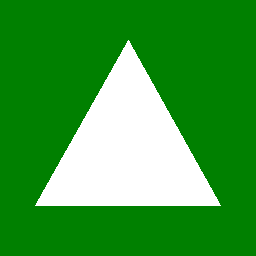

A white triangle on a green background


In [19]:

# Cell 18: Create a small image dataset

from PIL import Image, ImageDraw
from pathlib import Path

image_dir = Path("/content/rag_images")
image_dir.mkdir(exist_ok=True)

def make_sample_image(filename, background, shape, description):
    image = Image.new("RGB", (256, 256), background)
    draw = ImageDraw.Draw(image)

    if shape == "circle":
        draw.ellipse((55, 55, 200, 200), fill="white")
    elif shape == "square":
        draw.rectangle((55, 55, 200, 200), fill="white")
    elif shape == "triangle":
        draw.polygon(
            [(128, 40), (35, 205), (220, 205)],
            fill="white"
        )

    path = image_dir / filename
    image.save(path)

    return {
        "path": str(path),
        "description": description
    }


image_documents = [
    make_sample_image(
        "red_circle.png",
        "red",
        "circle",
        "A white circle on a red background"
    ),
    make_sample_image(
        "blue_square.png",
        "blue",
        "square",
        "A white square on a blue background"
    ),
    make_sample_image(
        "green_triangle.png",
        "green",
        "triangle",
        "A white triangle on a green background"
    )
]

for item in image_documents:
    display(Image.open(item["path"]))
    print(item["description"])


In [24]:
# Cell 19: Encode images with CLIP

import torch
import torch.nn.functional as F
from transformers import CLIPModel, CLIPProcessor
from PIL import Image

clip_name = "openai/clip-vit-base-patch32"

clip_processor = CLIPProcessor.from_pretrained(clip_name)
clip_model = CLIPModel.from_pretrained(clip_name).to(device).eval()

# Load and preprocess images
images = [
    Image.open(item["path"]).convert("RGB")
    for item in image_documents
]

image_inputs = clip_processor(
    images=images,
    return_tensors="pt"
).to(device)

# Extract image embeddings
with torch.no_grad():
    vision_outputs = clip_model.vision_model(
        pixel_values=image_inputs["pixel_values"],
        return_dict=True
    )

    # Project image features into CLIP's shared embedding space
    image_features = clip_model.visual_projection(
        vision_outputs.pooler_output
    )

# Convert to float32 and normalize for cosine similarity
image_features = F.normalize(
    image_features.float(),
    p=2,
    dim=-1
)

print("Image embedding shape:", image_features.shape)
print("Number of images:", image_features.shape[0])
print("Embedding dimension:", image_features.shape[-1])
print("Vector norms:", image_features.norm(dim=-1))


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Image embedding shape: torch.Size([3, 512])
Number of images: 3
Embedding dimension: 512
Vector norms: tensor([1.0000, 1.0000, 1.0000], device='cuda:0')


In [26]:

import torch
import torch.nn.functional as F

def multimodal_image_search(query, k=2):
    # Tokenize the text query
    text_inputs = clip_processor(
        text=[query],
        return_tensors="pt",
        padding=True,
        truncation=True
    ).to(device)

    # Encode the query using CLIP's text encoder
    with torch.no_grad():
        text_outputs = clip_model.text_model(
            input_ids=text_inputs["input_ids"],
            attention_mask=text_inputs.get("attention_mask"),
            return_dict=True
        )

        # Project text into CLIP's shared embedding space
        text_features = clip_model.text_projection(
            text_outputs.pooler_output
        )

    # Normalize query embedding
    text_features = F.normalize(
        text_features.float(),
        p=2,
        dim=-1
    )

    # Ensure image embeddings are normalized tensors
    image_vectors = F.normalize(
        image_features.float(),
        p=2,
        dim=-1
    )

    # Calculate cosine similarities
    similarities = (text_features @ image_vectors.T).squeeze(0)

    # Return the top-k matching images
    k = min(k, len(image_documents))
    scores, indices = torch.topk(similarities, k=k)

    results = []
    for score, idx in zip(scores.tolist(), indices.tolist()):
        results.append({
            "path": image_documents[idx]["path"],
            "score": score,
            "document": image_documents[idx]
        })

    return results


# Test image search
image_results = multimodal_image_search(
    "a triangle on a green background",
    k=2
)

for result in image_results:
    print(f"Image: {result['path']}")
    print(f"Cosine similarity: {result['score']:.4f}")
    print("-" * 40)


Image: /content/rag_images/green_triangle.png
Cosine similarity: 0.3424
----------------------------------------
Image: /content/rag_images/blue_square.png
Cosine similarity: 0.2489
----------------------------------------


In [30]:

# Cell 21: Retrieval evaluation using Recall@K and MRR

evaluation_set = [
    {
        "query": "What is retrieval augmented generation?",
        "relevant_ids": {"D1", "D7"}
    },
    {
        "query": "How do text embeddings represent meaning?",
        "relevant_ids": {"D3"}
    },
    {
        "query": "How do I split long documents into chunks?",
        "relevant_ids": {"D4"}
    },
    {
        "query": "How does dense passage retrieval work?",
        "relevant_ids": {"D6"}
    },
    {
        "query": "What is multimodal retrieval?",
        "relevant_ids": {"D10"}
    }
]


def evaluate_retriever(search_function, k=3):
    recalls = []
    reciprocal_ranks = []

    for example in evaluation_set:
        results = search_function(example["query"], k=k)

        ranked_ids = [item["id"] for item in results]
        relevant = example["relevant_ids"]

        recalls.append(
            len(set(ranked_ids) & relevant) / len(relevant)
        )

        rank = next(
            (
                rank
                for rank, doc_id in enumerate(ranked_ids, start=1)
                if doc_id in relevant
            ),
            None
        )

        reciprocal_ranks.append(
            1 / rank if rank is not None else 0
        )

    return {
        f"Recall@{k}": float(np.mean(recalls)),
        "MRR": float(np.mean(reciprocal_ranks))
    }


def semantic_search_for_eval(query, k=3):
    return vector_search(query, k=k)


def keyword_search_for_eval(query, k=3):
    return keyword_search_tool(query)[:k]


metrics = {
    "Semantic embeddings": evaluate_retriever(
        semantic_search_for_eval, k=3
    ),
    "Keyword BM25": evaluate_retriever(
        keyword_search_for_eval, k=3
    )
}

display(pd.DataFrame(metrics).T)


,Recall@3,MRR
Semantic embeddings,0.9,1.000000
Keyword BM25,0.8,0.666667


In [32]:

import torch
import torch.nn.functional as F

def multimodal_image_search(query, k=2):
    # Prepare text input
    text_inputs = clip_processor(
        text=[query],
        return_tensors="pt",
        padding=True,
        truncation=True
    ).to(device)

    # Extract text embeddings
    with torch.no_grad():
        output = clip_model.get_text_features(**text_inputs)

        # Handle Transformers versions with different output types
        if isinstance(output, torch.Tensor):
            text_features = output
        elif hasattr(output, "pooler_output"):
            text_features = clip_model.text_projection(
                output.pooler_output
            )
        elif hasattr(output, "text_embeds"):
            text_features = output.text_embeds
        else:
            raise TypeError(
                f"Unexpected CLIP output type: {type(output)}"
            )

    # Normalize text embedding
    text_features = F.normalize(
        text_features.float(), p=2, dim=-1
    )

    # Normalize previously generated image embeddings
    image_vectors = F.normalize(
        image_features.float(), p=2, dim=-1
    )

    # Compute cosine similarity
    similarities = (text_features @ image_vectors.T).squeeze(0)

    # Retrieve top-k matches
    k = min(k, len(image_documents))
    scores, indices = torch.topk(similarities, k=k)

    return [
        {
            "path": image_documents[i]["path"],
            "score": float(score),
            "document": image_documents[i]
        }
        for score, i in zip(scores.tolist(), indices.tolist())
    ]


# Test the updated function
image_results = multimodal_image_search(
    "a triangle on a green background",
    k=2
)

for result in image_results:
    print(f"Image: {result['path']}")
    print(f"Similarity: {result['score']:.4f}")
    print("-" * 40)


Image: /content/rag_images/green_triangle.png
Similarity: 0.0023
----------------------------------------
Image: /content/rag_images/blue_square.png
Similarity: -0.0048
----------------------------------------


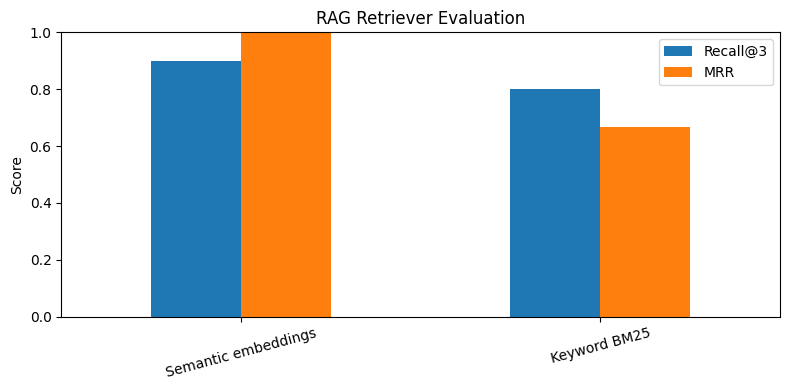

In [36]:

# Cell 22: Plot retrieval metrics

metrics_df = pd.DataFrame(metrics).T

metrics_df.plot(kind="bar", figsize=(8, 4))
plt.title("RAG Retriever Evaluation")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()
